要在失败后基于历史检查点恢复运行，需要满足以下条件：

1. 启用检查点存储器
   - 如果是 **`InMemorySaver`**，不要重建检查点存储器对象，否则历史检查点丢失，无法恢复
   - 如果希望跨进程、服务重启后仍可恢复，应使用基于 **`SQLite、Postgres`** 等持久化检查点后端的存储器
2. 再次运行时用 **`None`** 作为计算图的状态输入
3. 传递的配置信息应包含 **`thread_id`** 而不能包含 **`checkpoint_id`**

此时，**`LangGraph`** 会根据 **`thread_id`** 从 **`checkpointer`** 读取该会话的最新检查点，并从该检查点继续推进。

失败示例：

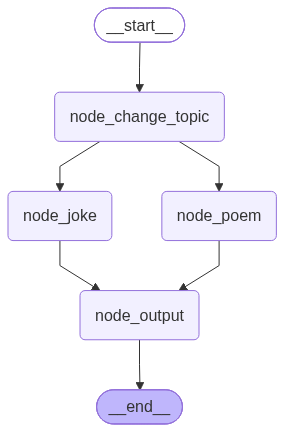

[
    StateSnapshot(
        values={'topic': '小猫：布偶猫'},
        next=('node_poem', 'node_joke'),
        config={
            'configurable': {
                'thread_id': 'chap06_002',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cd5b0-65f2-61a5-8001-c9d5f1611ee9'
            }
        },
        metadata={'step': 1, 'source': 'loop', 'parents': {}},
        created_at='2026-10-21T14:23:45.781187+00:00',
        parent_config={
            'configurable': {
                'thread_id': 'chap06_002',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cd5b0-65e8-66aa-8000-125401325597'
            }
        },
        tasks=(
            PregelTask(
                id='5639b181-5dea-9ed8-115e-494ac3eabdd6',
                name='node_poem',
                path=('__pregel_pull', 'node_poem'),
                error=None,
                interrupts=(),
                state=None,
                result={
                    'poem': 
'《咏布偶猫》\n蓝瞳映雪玉生柔，\n静理云裾性自幽。\n倦拥温存浑似水，\n闲偎暖帐不知秋。\n\n**【格律与用韵】**\n- 
本诗依《平水韵》下平十一尤韵（柔、幽、秋），平起首句入韵式。\n- 
平仄严谨，严守“一三五不论，二四六分明”及绝句正格，无孤平、三平尾等病。\n\n**【意象简析】**\n- 
**首句**点出布偶猫标志性的湛蓝眼眸与如雪蓬松的长毛；\n- **次句**以“云裾”喻其丰盈被毛，“性自幽”写其 temperament 
温和静雅；\n- 
**第三句**“浑似水”化用古典笔法，暗合布偶猫被人抱起时全身放松、如同融化般的著名特质（故得名“布偶”）；\n- 
**末句**收束于日常陪伴之境，不着痕而尽显人与猫相守的安宁岁月。'
                }
            ),
            PregelTask(
                id='4ad0b45a-8e7a-09ca-f19f-bd53362f7506',
                name='node_joke',
                path=('__pregel_pull', 'node_joke'),
                error="Exception('人为抛出异常')",
                interrupts=(),
                state=None,
                result=None
            )
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={'topic': '小猫'},
        next=('node_change_topic',),
        config={
            'configurable': {
                'thread_id': 'chap06_002',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cd5b0-65e8-66aa-8000-125401325597'
            }
        },
        metadata={'step': 0, 'source': 'loop', 'parents': {}},
        created_at='2026-10-21T14:23:45.777220+00:00',
        parent_config={
            'configurable': {
                'thread_id': 'chap06_002',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cd5b0-65e2-65da-bfff-da5beacf4c1b'
            }
        },
        tasks=(
            PregelTask(
                id='2db74739-df16-613e-5a22-965ecfcbab61',
                name='node_change_topic',
                path=('__pregel_pull', 'node_change_topic'),
                error=None,
                interrupts=(),
                state=None,
                result={'topic': '小猫：布偶猫'}
            ),
        ),
        interrupts=()
    ),
    StateSnapshot(
        values={},
        next=('__start__',),
        config={
            'configurable': {
                'thread_id': 'chap06_002',
                'checkpoint_ns': '',
                'checkpoint_id': '1f1cd5b0-65e2-65da-bfff-da5beacf4c1b'
            }
        },
        metadata={'step': -1, 'source': 'input', 'parents': {}},
        created_at='2026-10-21T14:23:45.774741+00:00',
        parent_config=None,
        tasks=(
            PregelTask(
                id='7e99de65-1dc9-9235-abb4-1350e277e87d',
                name='__start__',
                path=('__pregel_pull', '__start__'),
                error=None,
                interrupts=(),
                state=None,
                result={'topic': '小猫'}
            ),
        ),
        interrupts=()
    )
]

In [5]:
import time
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.config import RunnableConfig
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from loguru import logger
from dotenv import load_dotenv
from IPython.display import display
from rich import print as rprint
from langgraph.checkpoint.postgres import PostgresSaver
import os

load_dotenv(override=True)

qwen_model = init_chat_model(
    model="qwen3.7-flash",
    model_provider="openai",
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url=os.getenv("DASHSCOPE_BASE_URL"),
)
#1. 声明状态
class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    final_output: str
#1.1 输入状态
class InputState(TypedDict):
    topic: str

#1.2 输出状态
class OutputState(TypedDict):
    final_output: str

topics = ["布偶猫","狸花猫","金渐层"]
topic_index = 0

# 2. 定义节点
def node_change_topic(state: InputState) -> OverAllState:
    global topic_index
    logger.info("topic_index：{}", topic_index)
    sub_topic = topics[topic_index]
    topic_index += 1
    topic_index %= len(topics)
    return {
        "topic": f"{state['topic']}：{sub_topic}",
    }

#2.1 同一个超步的位置，成功运行的节点
def node_poem(state: OverAllState) -> OverAllState:
    logger.info("node_poem正在执行")
    topic = state["topic"]
    poem = qwen_model.invoke(
        [HumanMessage(f"写一首关于{topic}主题的七言绝句")],
    ).content
    return {
        "poem":poem
    }

#2.2 同一个超步的位置，运行失败的节点
def node_joke(state: OverAllState) -> OverAllState:
    logger.info("node_joke正在执行")
    topic = state["topic"]
    time.sleep(5)
    raise Exception("人为抛出异常")
    joke = qwen_model.invoke(
        [HumanMessage(f"写一段关于{topic}主题的笑话")],
    ).content
    return {
        "joke": joke,
    }

def node_output(state: OverAllState) -> OutputState:
    logger.info("node_output正在执行")
    topic = state["topic"]
    poem = state["poem"]
    joke = state["joke"]
    final_output = f"关于{topic}的七言绝句:{poem}\n 笑话:{joke}\n"
    return {
        "final_output":final_output
    }

#3. 构建图
builder = StateGraph(
    state_schema=OverAllState,
    input_schema=InputState,
    output_schema=OutputState
)

#3.1 添加节点
builder.add_node("node_change_topic",node_change_topic)
builder.add_node("node_poem",node_poem)
builder.add_node("node_joke",node_joke)
builder.add_node("node_output",node_output)

#3.2 添加边
builder.add_edge(START,"node_change_topic")
builder.add_edge("node_change_topic","node_poem")
builder.add_edge("node_change_topic","node_joke")
builder.add_edge("node_poem","node_output")
builder.add_edge("node_joke","node_output")
builder.add_edge("node_output",END)

DB_HOST = os.getenv("POSTGRE_DB_IP")
DB_USER = os.getenv("POSTGRE_DB_USER")
DB_PWD = os.getenv("POSTGRE_DB_PWD")
# 定义并在编译时传递 Checkepointer
DB_URL = f"postgresql://{DB_USER}:{DB_PWD}@{DB_HOST}:5432/langgraph_db?sslmode=disable"
with PostgresSaver.from_conn_string(DB_URL) as checkpointer_db:
    #5. 第一次使用PostgresSaver作为检查点 需要调用方法 setup()
    checkpointer_db.setup()
    graph = builder.compile(checkpointer=checkpointer_db)
    display(graph)

    myconfig: RunnableConfig = RunnableConfig(
        configurable={
            "thread_id": "chap06_002"
        }
    )
    state_history = list(graph.get_state_history(config=myconfig))
    # 执行下面的会报错。
    # resp = graph.invoke({"topic": "小猫"}, config=myconfig)
    rprint(state_history)

根据上面的代码，修复BUG之后恢复运行

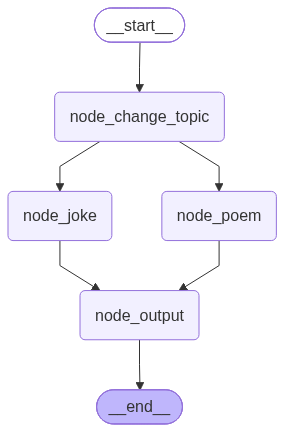

{
    'final_output': 
'关于小猫：布偶猫的七言绝句:这是一首为您定制的七言绝句，严格遵循古典诗词的平仄与押韵规范（仄起首句入韵，押《平水韵
》下平十一尤），并巧妙融入布偶猫的标志性特征：\n\n**《咏布偶猫》**\n碎雪裁成软玉裘，\n蓝睛似水洗春幽。\n娇慵恰似缠
枝柳，\n任尔呼名卧膝留。\n\n📖 **意象对照说明**：\n- 
**首句**以“碎雪”“软玉”喻其长而蓬松的被毛，暗合布偶猫“雪袍玉骨”的视觉印象；\n- 
**次句**点出布偶猫标志性的“宝石蓝”双眸，“似水洗春幽”写出其目光清澈、性情温顺的特质；\n- 
**第三句**“缠枝柳”专指该品种被人抱起或倚靠时全身松软下垂的经典体态（英文名Ragdoll本意即为“布娃娃”）；\n- 
**末句**“卧膝留”刻画其极亲人、爱待在人膝上的习性，呼应布偶猫“猫中天使”的粘人性格。\n\n全篇未直书 breed 
之名，而以古典笔法勾取其神貌，可题于画卷或宠物摄影之上。如需调整意境风格（如更偏童趣、或更重古雅），可告知为您微调
。\n 
笑话:有人问养布偶猫的朋友：“名字都叫布偶了，这猫是不是跟玩具一样，一拿起来就安静不动弹？”\n\n朋友叹了口气：“确实一
动不动……只要我手一抬，它‘啪嗒’一下就彻底断电，四肢自然下垂，尾巴搭在我腕子上，呼吸平稳得像开了睡眠模式。我当时心想
：白嫖了一只会呼吸的高定玩偶！\n\n直到我发现，这‘高级布偶’不仅掉毛像局部降雪，还每天准时跳上我的笔记本，用三根肉垫
敲键盘给我发微信语音：`[滴嘟] 罐头呢？`  
\n更离谱的是，我一坐下，它就自动往我腿边一摊，化身‘活体暖脚宝’，不仅恒温、带呼噜马达，还按月收费（纯粮+冻干）。\n\n
朋友追问：‘那你到底买的是猫，还是会讨债的玩偶？’  
\n我：‘布偶猫啊。主打一个“抱起来像没电玩偶，放下去像带了条狗，拆开一看全是毛”。’” 🐾💸\n'
}

In [7]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.config import RunnableConfig
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from loguru import logger
from dotenv import load_dotenv
from IPython.display import display
from rich import print as rprint
from langgraph.checkpoint.postgres import PostgresSaver
import os

load_dotenv(override=True)

qwen_model = init_chat_model(
    model="qwen3.7-flash",
    model_provider="openai",
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url=os.getenv("DASHSCOPE_BASE_URL"),
)
#1. 声明状态
class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    final_output: str
#1.1 输入状态
class InputState(TypedDict):
    topic: str

#1.2 输出状态
class OutputState(TypedDict):
    final_output: str

topics = ["布偶猫","狸花猫","金渐层"]
topic_index = 0

# 2. 定义节点
def node_change_topic(state: InputState) -> OverAllState:
    global topic_index
    logger.info("topic_index：{}", topic_index)
    sub_topic = topics[topic_index]
    topic_index += 1
    topic_index %= len(topics)
    return {
        "topic": f"{state['topic']}：{sub_topic}",
    }

#2.1 同一个超步的位置，成功运行的节点
def node_poem(state: OverAllState) -> OverAllState:
    logger.info("node_poem正在执行")
    topic = state["topic"]
    poem = qwen_model.invoke(
        [HumanMessage(f"写一首关于{topic}主题的七言绝句")],
    ).content
    return {
        "poem":poem
    }

#2.2 同一个超步的位置，运行失败的节点
def node_joke(state: OverAllState) -> OverAllState:
    logger.info("node_joke正在执行")
    topic = state["topic"]
    joke = qwen_model.invoke(
        [HumanMessage(f"写一段关于{topic}主题的笑话")],
    ).content
    return {
        "joke": joke,
    }

def node_output(state: OverAllState) -> OutputState:
    logger.info("node_output正在执行")
    topic = state["topic"]
    poem = state["poem"]
    joke = state["joke"]
    final_output = f"关于{topic}的七言绝句:{poem}\n 笑话:{joke}\n"
    return {
        "final_output":final_output
    }

#3. 构建图
builder = StateGraph(
    state_schema=OverAllState,
    input_schema=InputState,
    output_schema=OutputState
)

#3.1 添加节点
builder.add_node("node_change_topic", node_change_topic)
builder.add_node("node_poem", node_poem)
builder.add_node("node_joke", node_joke)
builder.add_node("node_output", node_output)

#3.2 添加边
builder.add_edge(START, "node_change_topic")
builder.add_edge("node_change_topic", "node_poem")
builder.add_edge("node_change_topic", "node_joke")
builder.add_edge("node_poem", "node_output")
builder.add_edge("node_joke", "node_output")
builder.add_edge("node_output", END)

DB_HOST = os.getenv("POSTGRE_DB_IP")
DB_USER = os.getenv("POSTGRE_DB_USER")
DB_PWD = os.getenv("POSTGRE_DB_PWD")
# 定义并在编译时传递 Checkepointer
DB_URL = f"postgresql://{DB_USER}:{DB_PWD}@{DB_HOST}:5432/langgraph_db?sslmode=disable"
with PostgresSaver.from_conn_string(DB_URL) as checkpointer_db:
    #5. 第一次使用PostgresSaver作为检查点 需要调用方法 setup()
    checkpointer_db.setup()
    graph = builder.compile(checkpointer=checkpointer_db)
    display(graph)

### 恢复运行的话，只需thread_id 和 invoke None
    myconfig: RunnableConfig = RunnableConfig(
        configurable={
            "thread_id": "chap06_002"
        }
    )
    resp = graph.invoke(None, config=myconfig)
    rprint(resp)